# 29 — Warm-start (initial-state) protocol study, System I (fixed controller law)

## Selection criterion — fixed before any result was computed

The initial state of each simulated window is part of the generative model: it encodes
an assumption about how the fault evolves relative to the 60-min window. Choosing the
protocol that looks best on data generated with that same protocol is circular.

**"Optimal" = matches the situation the monitor faces, and degrades gracefully under
mismatch.** The realistic deployment case is an *incipient* fault (test column **P2**:
θ drifts at the 30-day degradation rates, noise on throughout). Rule (implemented in
`scripts/nb29_ws_study.py::stage_select`):

1. **Eligible** = on the P2 column, seed-median marginal SBC KS p ≥ 0.01 for α and β
   **and** seed-median TARP KS p ≥ 0.01 (joint calibration, sensitive to a wrong α–β correlation).
2. Among eligible: lowest seed-mean normalised posterior-mean RMSE on P2; protocols within
   one combined standard error are tied.
3. Tie-break 1: smallest worst-case TARP deviation over the other incipient-fault columns
   (P1, P1b, P3). The abrupt-fault column P0 is a different regime and is reported only.
4. Tie-break 2: simplicity / cost, P1 < P1b < P3 < P2 < P0.
5. If nothing is eligible: lowest P2 TARP deviation, **flagged**; nb31 does not start.

| Protocol | Initial state | Assumption |
|---|---|---|
| P0 | healthy steady state for every θ | abrupt fault at window start |
| P1 | deterministic steady state at θ | incipient fault, noise-free start |
| P1b | P1 + 150-min noisy burn-in | incipient fault, stationary start |
| P2 | θ ramps over a 300-min noisy history at 30-day rates | incipient fault, realistic |
| P3 | steady state at θ′ = θ + N(0, 0.03²) | initial state uncertain (nuisance) |

**Running this notebook.** Execute top to bottom from `notebooks/system_I`. Every stage
skips work already saved in `results/29fx/` and `results/29fx_*.csv`, so after an
interruption simply re-run. Progress sentinels: `results/29fx_progress_*.txt`.


> **Sensor model: N3** (N3: sigma_C=0.01 mol/L, sigma_T=0.2 K, sigma_Tc=0.2 K, sigma_Qc=2.0 L/min). This notebook re-runs the protocol study under the
> production sensor model adopted on 2026-11-09 after notebook 33. The N0 run is
> `29_warm_start_protocol_study.ipynb` (kept for the SI). Same criterion, same seeds; outputs
> carry the prefix `29fx_N3_`. Purpose: show that the protocol choice (P1b) does not depend on
> the sensor model, and report the N3 protocol-mismatch effects for the paper.
> **Outcome (2026-11-09):** under N3 the rule selected **P2** (not P1b); the user adopted P2 as the N3 production protocol, with P1b reported side by side (see the Review and Interpretation cells). The N0 production protocol stays P1b.

In [1]:
import json, os, sys, time, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", \
    f"execute this notebook from notebooks/system_I (cwd is {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
import importlib, ws_protocols, ws_eval, system_I_config, nb29_ws_study
for _m in (system_I_config, ws_protocols, ws_eval, nb29_ws_study):
    importlib.reload(_m)
S = nb29_ws_study
assert S.SENSOR == "N3", S.SENSOR
R, FIGS = ROOT / "results", ROOT / "figures"
P = S.PROTOCOLS

# ---- run switches -----------------------------------------------------------------
PARALLEL_TRAINING = False   # True: train protocol groups in parallel subprocesses (cwd = this folder)
RUN_E4 = False              # optional window-length check (~1-2 h)
THREADS = 4
T0 = time.time()

def load(name):
    f = R / name
    return pd.read_csv(f) if f.exists() else None

## E1 — time scales (deterministic)
Closed-loop eigen time constants, burn-in to stationarity from the exact Lyapunov
solution (no noisy ensemble estimate), settling after an abrupt fault (noise-free,
tolerances far above float32 precision), and the P2 plant lag at realistic and 10× rates.
Replaces the superseded old-law `29_e1_*` files.

**Check:** slowest τ 10–26 min at unsaturated points; `t95_stationary_min` below the
150-min P1b burn-in; finite settling; `lag_Qc_x1` ≲ 3 L/min.

In [2]:
if not (R / f"{S.TAG}_e1_timescales.csv").exists():
    S.stage_e1()
e1 = load(f"{S.TAG}_e1_timescales.csv"); display(e1.round(4))
assert e1.loc[~e1.saturated_ss, "t95_stationary_min"].max() < 150, \
    "P1b burn-in (150 min) shorter than the time to stationarity: raise burn_min in ws_protocols before E3"


,point,alpha,beta,saturated_ss,Qc_ss,T_ss,slowest_tau_min,fastest_tau_min,min_zeta,t95_stationary_min,t_settle_abrupt_min,sd_T_stat,sd_Qc_stat,lag_Qc_x1,lag_T_x1,lag_C_rel_x1,lag_Qc_x10,lag_T_x10,lag_C_rel_x10
0,Sc1,1.00,1.00,False,43.0655,312.5000,9.9750,0.2366,1.0000,21.0,0.0,0.1381,24.1616,-0.5444,0.0000,-0.0000,-0.8248,0.0013,-0.0001
1,Sc2,1.00,0.70,True,400.0000,312.8690,10.2361,0.0979,1.0000,16.0,53.5,0.2346,0.0000,0.0000,-0.0152,0.0014,0.0000,-0.0161,0.0015
2,Sc3,0.70,1.00,False,36.3422,312.5000,9.9568,0.3393,0.9783,19.0,6.0,0.1314,22.1332,-0.3727,0.0000,-0.0000,-0.6916,0.0007,-0.0001
3,Sc4,0.85,0.85,False,92.2729,312.5000,18.8983,0.2789,1.0000,46.0,inf,0.1927,49.3082,-3.3694,0.0000,-0.0000,-5.9325,0.0067,-0.0006
4,Sc5,1.00,0.40,True,400.0000,314.1836,11.0909,0.0988,1.0000,17.0,38.0,0.2433,0.0000,0.0000,-0.0172,0.0016,0.0000,-0.0169,0.0015
5,Sc7,1.00,0.85,False,109.8563,312.5000,26.4083,0.2366,1.0000,56.0,inf,0.2000,57.3231,-4.7911,0.0000,-0.0000,-8.9476,0.0085,-0.0008
6,"c(0.4,0.4)",0.40,0.40,True,400.0000,313.7622,11.0319,0.0988,1.0000,17.0,37.0,0.2527,0.0000,0.0000,-0.0168,0.0015,0.0000,-0.0175,0.0016
7,"c(0.4,1.2)",0.40,1.20,False,18.8811,312.5000,9.9636,0.5876,0.4499,14.0,15.0,0.1092,16.8516,0.0286,0.0000,-0.0000,0.1307,-0.0002,-0.0000
8,"c(1.2,0.4)",1.20,0.40,True,400.0000,314.2297,11.0970,0.0988,1.0000,17.0,38.0,0.2423,0.0000,0.0000,-0.0172,0.0016,0.0000,-0.0167,0.0015
9,"c(1.2,1.2)",1.20,1.20,False,28.6061,312.5000,9.9842,0.1967,0.6991,17.0,9.5,0.1122,17.8631,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


**Reading E1 (2026-11-08 run).** The eigen time constants (10–26 min) and the exact
Lyapunov burn-in (`t95_stationary_min` 14–56 min, all below the 150-min P1b burn-in) are
the reliable E1 numbers. The two noise-free columns are **not**: `t_settle_abrupt_min = inf`
at Sc4/Sc7 and the `lag_Qc_*` offsets (−3 to −5 L/min, not proportional to the rate
multiplier) come from float32 stalling of the integrator in a run with *no* noise (state
increments below one ulp of T ≈ 312 K). The stochastic simulator is unaffected (each
noise increment, ~0.01 K, is far above the ulp). Do not cite those two columns; if needed,
recompute them in a float64 subprocess.

## E2 — where the information is (Fisher information per protocol and representation)
Gaussian FIM with common random numbers. `corr_implied` is the correlation of the inverse
FIM (the local posterior correlation). Representations: 29-D summaries with full vs diagonal
covariance, the raw 120×4 trajectory (Ledoit–Wolf covariance), and the four channel means
only (the "level" information).

In [3]:
if not (R / f"{S.TAG}_e2_fim.csv").exists():
    S.stage_e2()
e2 = load(f"{S.TAG}_e2_fim.csv")
display(e2.pivot_table(index=["point", "representation"], columns="protocol", values="corr_implied").round(3))
display(e2.pivot_table(index=["point", "representation"], columns="protocol", values="crb_sd_b").round(4))

protocol                    P0     P1    P1b     P2     P3
point representation                                      
Sc1   channel_means      0.179  0.158  0.099  0.101  0.158
      raw_traj_lwcov     0.183  0.251  0.131  0.120  0.199
      summaries_diagcov  0.206  0.177  0.174  0.178  0.177
      summaries_fullcov  0.068  0.092  0.013  0.038  0.086
Sc2   channel_means      0.185  0.132  0.085  0.086  0.126
      raw_traj_lwcov     0.157  0.220  0.109  0.093  0.160
      summaries_diagcov  0.331  0.293  0.296  0.301  0.293
      summaries_fullcov  0.079  0.173  0.082  0.089  0.142
Sc3   channel_means      0.182  0.154  0.094  0.096  0.154
      raw_traj_lwcov     0.175  0.235  0.123  0.110  0.195
      summaries_diagcov  0.201  0.172  0.169  0.170  0.172
      summaries_fullcov  0.059  0.080  0.014  0.034  0.077
Sc4   channel_means      0.186  0.218  0.133  0.130  0.179
      raw_traj_lwcov     0.173  0.521  0.176  0.150  0.207
      summaries_diagcov  0.265  0.257  0.248  0.250  0.262
      summaries_fullcov  0.057  0.363  0.083  0.086  0.110

protocol                     P0      P1     P1b      P2      P3
point representation                                           
Sc1   channel_means      0.0410  0.0367  0.0384  0.0382  0.0369
      raw_traj_lwcov     0.0319  0.0163  0.0313  0.0310  0.0223
      summaries_diagcov  0.0200  0.0196  0.0197  0.0195  0.0196
      summaries_fullcov  0.0154  0.0141  0.0156  0.0155  0.0145
Sc2   channel_means      0.0337  0.0233  0.0247  0.0242  0.0241
      raw_traj_lwcov     0.0246  0.0155  0.0204  0.0196  0.0186
      summaries_diagcov  0.0126  0.0138  0.0131  0.0126  0.0138
      summaries_fullcov  0.0244  0.0199  0.0243  0.0235  0.0229
Sc3   channel_means      0.0418  0.0380  0.0395  0.0392  0.0382
      raw_traj_lwcov     0.0327  0.0179  0.0328  0.0324  0.0232
      summaries_diagcov  0.0220  0.0215  0.0216  0.0214  0.0215
      summaries_fullcov  0.0159  0.0147  0.0163  0.0162  0.0150
Sc4   channel_means      0.0396  0.0211  0.0297  0.0296  0.0277
      raw_traj_lwcov     0.0292  0.0069  0.0230  0.0222  0.0199
      summaries_diagcov  0.0148  0.0114  0.0115  0.0114  0.0106
      summaries_fullcov  0.0176  0.0092  0.0167  0.0166  0.0160

## E3 — train-protocol × test-protocol matrix (5k sims, 3 seeds, equal budget)
### E3a — simulate training banks and test sets
Same θ draws (and seeds) for every protocol, so protocols differ only by the initial state.

In [4]:
S.stage_e3sim()

### E3b — train 5 protocols × 3 seeds
Sequential by default (~2–3 h). With `PARALLEL_TRAINING = True`, two subprocesses are
launched from this folder and the cell waits for both.

In [5]:
if PARALLEL_TRAINING:
    groups = [("P0,P1", THREADS), ("P1b,P2,P3", THREADS)]
    procs = [subprocess.Popen([sys.executable, str(ROOT / "scripts" / "nb29_ws_study.py"), "e3train",
                               "--protocols", g, "--threads", str(t)], cwd=NB_DIR,
                              stdout=open(R / f"{S.TAG}_train_{g.replace(',', '_')}.log", "w"),
                              stderr=subprocess.STDOUT) for g, t in groups]
    codes = [p.wait() for p in procs]
    assert all(c == 0 for c in codes), f"training subprocess failed: {codes} (see results/{S.TAG}_train_*.log)"
else:
    S.stage_e3train(P, list(range(S.N_SEEDS)), THREADS)
print(sorted(f.name for f in S.OUT.glob("post_*.pkl")))

['post_P0_s0.pkl', 'post_P0_s1.pkl', 'post_P0_s2.pkl', 'post_P1_s0.pkl', 'post_P1_s1.pkl', 'post_P1_s2.pkl', 'post_P1b_s0.pkl', 'post_P1b_s1.pkl', 'post_P1b_s2.pkl', 'post_P2_s0.pkl', 'post_P2_s1.pkl', 'post_P2_s2.pkl', 'post_P3_s0.pkl', 'post_P3_s1.pkl', 'post_P3_s2.pkl']


### E3c — evaluate every posterior on every test column

In [6]:
S.stage_e3eval()

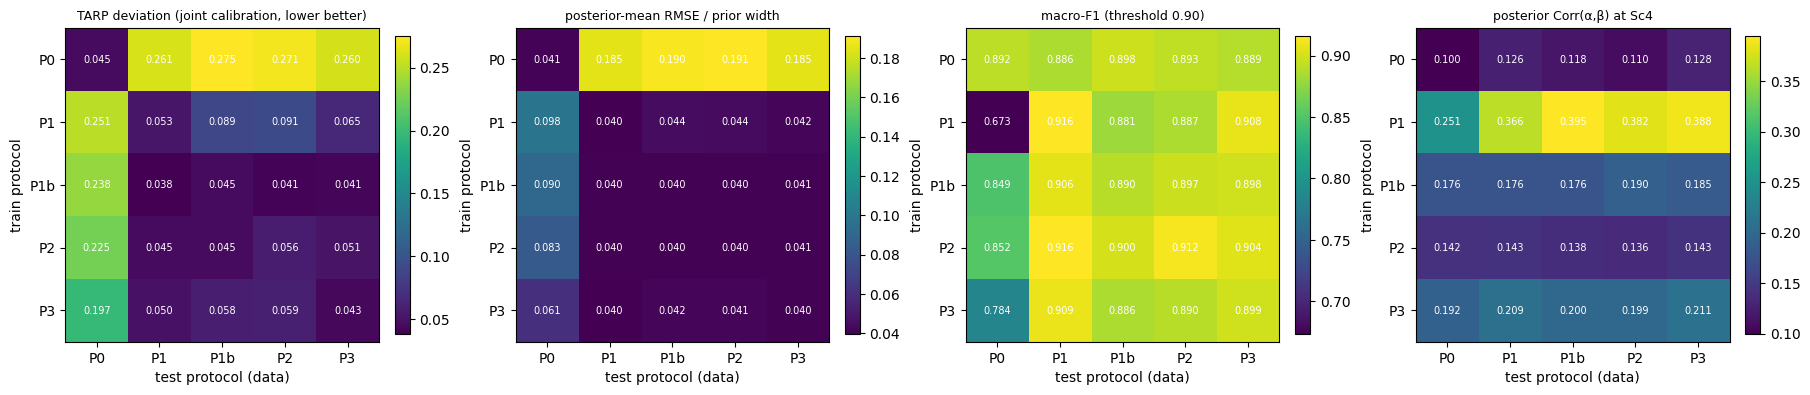

ks_p_a        ks_p_b        tarp_ks_p        tarp_dev        cov90_a  \
        mean    std   mean    std      mean    std     mean    std    mean   
train                                                                        
P0     0.000  0.000  0.000  0.000     0.000  0.000    0.271  0.055   0.473   
P1     0.016  0.019  0.000  0.000     0.005  0.009    0.091  0.021   0.875   
P1b    0.020  0.029  0.116  0.112     0.372  0.388    0.041  0.013   0.854   
P2     0.084  0.068  0.026  0.007     0.174  0.273    0.056  0.017   0.873   
P3     0.060  0.076  0.001  0.002     0.130  0.156    0.059  0.019   0.870   

              ... corr_Sc1        corr_Sc2        corr_Sc3        corr_Sc4  \
         std  ...     mean    std     mean    std     mean    std     mean   
train         ...                                                            
P0     0.011  ...    0.076  0.081    0.128  0.033    0.037  0.053    0.110   
P1     0.030  ...    0.131  0.077    0.429  0.048    0.125  0.046    0.382   
P1b    0.003  ...    0.051  0.067    0.199  0.035    0.033  0.050    0.190   
P2     0.006  ...    0.041  0.072    0.131  0.041    0.043  0.040    0.136   
P3     0.023  ...    0.086  0.085    0.196  0.030    0.079  0.029    0.199   

             corr_Sc7         
         std     mean    std  
train                         
P0     0.031    0.042  0.058  
P1     0.052    0.026  0.058  
P1b    0.056    0.024  0.025  
P2     0.041    0.030  0.054  
P3     0.037    0.029  0.048  

[5 rows x 28 columns]

In [7]:
m = load(f"{S.TAG}_e3_matrix.csv")
metrics = [("tarp_dev", "TARP deviation (joint calibration, lower better)"),
           ("rmse_norm", "posterior-mean RMSE / prior width"),
           ("macro_f1", "macro-F1 (threshold 0.90)"),
           ("corr_Sc4", "posterior Corr(α,β) at Sc4")]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), constrained_layout=True)
for ax, (k, title) in zip(axes, metrics):
    tab = m.groupby(["train", "test"])[k].mean().unstack().reindex(index=P, columns=P)
    im = ax.imshow(tab.values, cmap="viridis")
    ax.set_xticks(range(5), P); ax.set_yticks(range(5), P)
    ax.set_xlabel("test protocol (data)"); ax.set_ylabel("train protocol"); ax.set_title(title, fontsize=9)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{tab.values[i, j]:.3f}", ha="center", va="center", color="w", fontsize=7)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(FIGS / f"{S.TAG}_e3_matrix.png", dpi=150); plt.show()
cols = ["ks_p_a", "ks_p_b", "tarp_ks_p", "tarp_dev", "cov90_a", "cov90_b", "rmse_norm", "macro_f1",
        "leak_sbc_mean", "corr_Sc1", "corr_Sc2", "corr_Sc3", "corr_Sc4", "corr_Sc7"]
display(m[m.test == "P2"].groupby("train")[cols].agg(["mean", "std"]).round(3))

### Per-scenario detail on the decision column (P2)

In [8]:
sc = load(f"{S.TAG}_e3_scenarios.csv")
display(sc[sc.test == "P2"].groupby(["train", "scenario"])[
    ["alpha_hat", "beta_hat", "bias_a", "bias_b", "cov90_truth_a", "cov90_truth_b",
     "corr_ab_mean", "class_acc"]].mean().round(3))

alpha_hat  beta_hat  bias_a  bias_b  \
train scenario                                                    
P0    Sc1_closed_healthy        0.995     0.994  -0.005  -0.006   
      Sc2_closed_fouling        1.021     0.820   0.021  -0.030   
      Sc3_closed_decay          0.709     0.998   0.009  -0.002   
      Sc4_closed_combined       0.865     0.826   0.015  -0.024   
      Sc5_closed_saturated      1.119     0.633   0.119   0.133   
      Sc7_closed_drift          0.935     0.441  -0.065  -0.409   
P1    Sc1_closed_healthy        0.998     0.971  -0.002  -0.029   
      Sc2_closed_fouling        1.013     0.844   0.013  -0.006   
      Sc3_closed_decay          0.710     0.981   0.010  -0.019   
      Sc4_closed_combined       0.860     0.850   0.010   0.000   
      Sc5_closed_saturated      1.014     0.512   0.014   0.012   
      Sc7_closed_drift          0.917     0.438  -0.083  -0.412   
P1b   Sc1_closed_healthy        0.992     0.991  -0.008  -0.009   
      Sc2_closed_fouling        1.009     0.851   0.009   0.001   
      Sc3_closed_decay          0.706     0.996   0.006  -0.004   
      Sc4_closed_combined       0.855     0.855   0.005   0.005   
      Sc5_closed_saturated      1.010     0.504   0.010   0.004   
      Sc7_closed_drift          0.904     0.441  -0.096  -0.409   
P2    Sc1_closed_healthy        0.994     0.997  -0.006  -0.003   
      Sc2_closed_fouling        1.012     0.852   0.012   0.002   
      Sc3_closed_decay          0.707     1.002   0.007   0.002   
      Sc4_closed_combined       0.857     0.858   0.007   0.008   
      Sc5_closed_saturated      1.019     0.504   0.019   0.004   
      Sc7_closed_drift          0.912     0.429  -0.088  -0.421   
P3    Sc1_closed_healthy        0.994     0.982  -0.006  -0.018   
      Sc2_closed_fouling        1.010     0.848   0.010  -0.002   
      Sc3_closed_decay          0.709     0.988   0.009  -0.012   
      Sc4_closed_combined       0.859     0.851   0.009   0.001   
      Sc5_closed_saturated      1.009     0.508   0.009   0.008   
      Sc7_closed_drift          0.907     0.433  -0.093  -0.417   

                            cov90_truth_a  cov90_truth_b  corr_ab_mean  \
train scenario                                                           
P0    Sc1_closed_healthy            0.911          0.867         0.076   
      Sc2_closed_fouling            0.889          0.589         0.128   
      Sc3_closed_decay              0.822          0.778         0.037   
      Sc4_closed_combined           0.856          0.667         0.110   
      Sc5_closed_saturated          0.111          0.000        -0.108   
      Sc7_closed_drift              0.489          0.000         0.042   
P1    Sc1_closed_healthy            0.911          0.611         0.131   
      Sc2_closed_fouling            0.900          0.344         0.429   
      Sc3_closed_decay              0.833          0.744         0.125   
      Sc4_closed_combined           0.889          0.311         0.382   
      Sc5_closed_saturated          0.956          0.778         0.079   
      Sc7_closed_drift              0.689          0.011         0.026   
P1b   Sc1_closed_healthy            0.900          0.844         0.051   
      Sc2_closed_fouling            0.889          0.778         0.199   
      Sc3_closed_decay              0.822          0.856         0.033   
      Sc4_closed_combined           0.900          0.767         0.190   
      Sc5_closed_saturated          0.956          0.889         0.076   
      Sc7_closed_drift              0.644          0.000         0.024   
P2    Sc1_closed_healthy            0.889          0.944         0.041   
      Sc2_closed_fouling            0.922          0.767         0.131   
      Sc3_closed_decay              0.822          0.844         0.043   
      Sc4_closed_combined           0.889          0.744         0.136   
      Sc5_closed_saturated          0.922          0.889         0.116   
      Sc7_closed_drift           

## Selection (applies the pre-set rule)

In [9]:
S.stage_select()
sel = json.loads((R / f"{S.TAG}_selection.json").read_text())
print("CHOICE:", sel["choice"])
if sel["flag"]:
    print("FLAG:", sel["flag"])

       min_ks_med  tarp_ks_med  tarp_dev    rmse  rmse_se      f1  n_seeds  worst_offcol_tarp_dev  P0col_tarp_dev  P0col_rmse  eligible
train                                                                                                                                  
P0         0.0000       0.0000    0.2713  0.1913   0.0391  0.8931        3                 0.2753          0.0447      0.0411     False
P1         0.0000       0.0001    0.0913  0.0443   0.0008  0.8865        3                 0.0887          0.2507      0.0978     False
P1b        0.0069       0.1932    0.0407  0.0402   0.0005  0.8966        3                 0.0453          0.2380      0.0902     False
P2         0.0215       0.0163    0.0560  0.0402   0.0002  0.9123        3                 0.0507          0.2253      0.0825      True
P3         0.0000       0.0837    0.0587  0.0415   0.0001  0.8898        3                 0.0580          0.1973      0.0608     False
eligible: ['P2']; best RMSE P2; tied within 1 SE

## Review — automatic under the pre-set conditions (proposed 2026-11-09, user confirmation in the N3 runbook)
Under N0 the selection was flagged because the full-set α SBC test failed for *every* protocol,
including matched train/test pairs (an estimator-budget limit, not a protocol property), and the
user approved the fallback P1b. For this re-run the same resolution is pre-approved **only
if all of the following hold**; otherwise the cell stops the pipeline for user review:
1. the selection is P1b;
2. if flagged, the cause is the same: the full-set α KS test fails (p < 0.01, seed median) on
   the matched diagonal of every protocol;
3. on the P2 column, P1b passes β (KS p ≥ 0.01) and the joint TARP test (p ≥ 0.01).

In [10]:
sel = json.loads((R / f"{S.TAG}_selection.json").read_text())
m = load(f"{S.TAG}_e3_matrix.csv")
diag_alpha_fails = all(m[(m.train == p) & (m.test == p)].ks_p_a.median() < 0.01 for p in P)
p1b = m[(m.train == "P1b") & (m.test == "P2")]
p1b_ok = (p1b.ks_p_b.median() >= 0.01) and (p1b.tarp_ks_p.median() >= 0.01)
print("choice", sel["choice"], "| flagged", bool(sel["flag"]), "| alpha fails on every matched pair", diag_alpha_fails,
      "| P1b passes beta and TARP on P2", p1b_ok)
_rv = R / f"{S.TAG}_selection_review.json"
_rev = json.loads(_rv.read_text()) if _rv.exists() else {}
if _rev.get("approved") and _rev.get("choice") == sel["choice"] and "user" in str(_rev.get("by", "")).lower():
    print(f"user decision on file: {_rev['choice']} approved by {_rev['by']} ({_rev.get('time', '')})")
    print("reason:", _rev.get("reason", ""))
elif sel["choice"] != "P1b":
    raise RuntimeError("STOP: under this sensor model the rule selects " + sel["choice"] + ", not P1b -- user review needed")
elif sel["flag"]:
    if not (diag_alpha_fails and p1b_ok):
        raise RuntimeError("STOP: selection flagged for a different reason than under N0 -- user review needed")
    (R / f"{S.TAG}_selection_review.json").write_text(json.dumps({
        "choice": "P1b", "approved": True, "time": time.ctime(),
        "by": "pre-approval conditions proposed 2026-11-09 (runbook docs/Manuscript/system_i_N3_runbook.md); all three met",
        "reason": "flag caused by full-set alpha SBC failing on every matched pair (budget limit), as under N0"}, indent=2))
    print("pre-approved: P1b (review file written)")
else:
    print("not flagged: P1b selected directly")

choice P2 | flagged False | alpha fails on every matched pair False | P1b passes beta and TARP on P2 True
user decision on file: P2 approved by user (Simone Casolo), 2026-11-09, in conversation with Claude (Mon Nov  9 08:10:38 2026)
reason: Pre-set nb29 rule selects P2 under N3 (only protocol passing the P2-column calibration gate: min KS median 0.021, TARP KS 0.016; P1b min KS 0.0069, TARP 0.19; RMSE equal 0.0402). Rule followed rather than overridden; margins are small (near-tie), so P1b is reported side by side in the paper. N0 production stays P1b (SI).


## Interpretation (N3 run) — written 2026-11-09

**Result in one sentence.** Under the production sensor model N3 the protocol story of the N0 study holds: a start that does not match the situation (abrupt fault, P0; noise-free start, P1) gives an overconfident β and, for P1, an invented α–β correlation, while the three noisy, incipient-fault protocols (P1b, P2, P3) are near-equal on accuracy; the pre-set rule selects **P2** over P1b by a small margin that rests on one P1b seed, and the user adopted P2 (P1b is reported side by side). This supports claim 3 (the warm-start protocol and the sensor model, not the estimator, explain the old β bias and α–β correlation); it does not by itself establish claim 2 (calibration), which is settled at the production budget in notebook 31.

**1. E1 (deterministic, independent of the sensor model; identical to N0).** Closed-loop time constants 10.0–26.4 min at the unsaturated points; the noise-induced spread reaches 95% of its stationary value within 14–56 min, so the 150-min P1b burn-in and the 300-min P2 history are several settling times long. Only these two columns are cited: the notebook's own note applies (the noise-free `t_settle_abrupt_min` and `lag_Qc_*` columns are float32 artefacts and are not used).

**2. E2: what realistic sensors change in the information.** Summary-based Cramér–Rao bound (full covariance, P1b) under N3 against N0: α sd 0.051 / 0.025 / 0.037 at Sc1 / Sc3 / Sc4 against 0.0015 / 0.0010 / 0.0014, i.e. 25–35× wider; β sd 0.0156 / 0.0163 / 0.0167 against 0.0361 / 0.0370 / 0.0277, i.e. 1.7–2.3× tighter. This reproduces the notebook-33 result (α ≈ 0.03–0.06, β ≈ 0.015). The raw-trajectory bound (Ledoit–Wolf covariance) is *looser* than the summary bound for β under N3 (0.031 vs 0.016 at Sc1, P1b); an exact bound cannot be, so this is shrinkage loss, and the summary bound is the β reference. *The noise-free start P1 still overstates β precision:* β sd at Sc4 0.0092 (summaries) and 0.0069 (raw) under P1 against 0.0167 and 0.0230 under P1b, i.e. 1.8× and 3.3× too small (N0: 3.0× and 4.3×). *The artefact correlation changes sign with the sensor model:* the Fisher-implied Corr(α, β) at Sc4 under P1 is **−0.69 (summaries) and −0.50 (raw) under N0, and +0.36 and +0.52 under N3**, while the other protocols stay within 0.06–0.11 (summaries) and 0.15–0.21 (raw) under N3. The robust statement is that a noise-free start overstates β precision and creates a correlation that is not in the plant, whose sign depends on the sensor model; it is a sharper version of the artefact-correlation result of notebook 33 §7. *Labelling:* the E2 point called "Sc2" is **β = 0.70 (saturating)**, the position before the catalogue change, not today's Sc2 (β = 0.85); its β bound (0.024) is therefore not comparable with notebook 33's Sc2 (0.016).

**3. E3: the matrix (5000 simulations, three seeds per protocol).** On the P2 test column (mean over 3 seeds), P0-trained and P1-trained posteriors fail under N3 as under N0: TARP deviation 0.271 (P0) and 0.091 (P1) against 0.041 (P1b), 0.056 (P2) and 0.059 (P3); β 90% coverage 0.41 (P0) and 0.72 (P1) against 0.86 (P1b), 0.87 (P2) and 0.80 (P3); β marginal KS p ≈ 0 for P0 and P1. The N0 values are similar (TARP 0.266 / 0.093; β coverage 0.49 / 0.77), so P0 and P1 fail under both sensor models. *The old β bias:* trained on P0 and evaluated on the incipient-fault column, β̂ is 0.820 at the current Sc2 (true 0.85; coverage 0.59), 0.826 at Sc4 (0.667) and 0.633 at Sc5 (true 0.50; coverage 0.00), while P1b and P2 recover 0.851–0.852, 0.855–0.858 and 0.504. The N0 run, at the old catalogue point β = 0.70, gave −0.145 (coverage 0.00); the two are at different β and are not directly comparable, but the mechanism (training/evaluation initial-state mismatch gives a biased, overconfident β) reproduces under N3. *The invented correlation:* the SBI Corr(α, β) at Sc4 on the P2 column is **+0.38 ± 0.05 under P1** (N0: −0.11), against +0.19 ± 0.06 (P1b), +0.14 ± 0.04 (P2) and +0.20 ± 0.04 (P3); the matched protocols keep a small positive correlation (the Fisher-implied value is +0.08 to +0.09).

*Side by side, P1b and P2 (P2 test column, per seed; for P2 this is also the matched diagonal):*

| | P1b s0 | P1b s1 | P1b s2 | P2 s0 | P2 s1 | P2 s2 |
|---|---|---|---|---|---|---|
| α marginal KS p | 0.007 | 0.000 | 0.054 | 0.008 | 0.136 | 0.108 |
| β marginal KS p | 0.124 | 0.000 | 0.224 | 0.034 | 0.021 | 0.022 |
| TARP KS p | 0.817 | 0.193 | 0.104 | 0.489 | 0.016 | 0.016 |
| TARP deviation | 0.026 | 0.046 | 0.050 | 0.036 | 0.066 | 0.066 |
| interior KS p (α / β) | 0.255 / 0.170 | 0.032 / 0.000 | 0.239 / 0.457 | 0.278 / 0.038 | 0.539 / 0.127 | 0.573 / 0.052 |
| normalised RMSE | 0.039 | 0.041 | 0.041 | 0.040 | 0.040 | 0.041 |
| macro-F1 | 0.918 | 0.875 | 0.897 | 0.918 | 0.915 | 0.904 |
| β 90% coverage | 0.886 | 0.844 | 0.852 | 0.874 | 0.870 | 0.854 |
| Corr(α, β) at Sc4 | 0.208 | 0.235 | 0.127 | 0.167 | 0.089 | 0.151 |

On the matched diagonal P1b is trained and tested on itself: α KS p 0.006 / 0.000 / 0.121, β KS p 0.000 / 0.018 / 0.056, TARP KS p 0.075 / 0.305 / 0.332. *Reading.* Accuracy is a tie (RMSE 0.0402 ± 0.0005 for P1b, 0.0402 ± 0.0002 for P2; macro-F1 0.897 ± 0.022 and 0.912 ± 0.007). P1b has the better TARP deviation (0.041 ± 0.013 against 0.056 ± 0.017) and median TARP p (0.19 against 0.016); P2 passes the gate on the seed medians (α KS p 0.108, β 0.022, TARP 0.016) because P1b's seed 1 fails every marginal test (α 0.000, β 0.000) and its seed-median α KS p, 0.0069, falls just under the 0.01 gate. The selection of P2 therefore comes from one seed of one protocol and a gate of 0.01 with n = 3; both protocols are marginal on α (the α marginal KS p is ≤ 0.14 for every seed of both), and none of this establishes that P2 is better than P1b. P2 is the protocol that matches the deployment situation (a plant that has been drifting slowly), which is the reason the rule uses the P2 column. The remaining calibration question is for the production budget (notebook 31), where the posterior is trained on a much larger bank than the 5000 simulations used here.

*Unmodelled drift is not a protocol effect.* At Sc7 (mild fouling + 2 K sensor drift) every training protocol gives β̂ ≈ 0.43–0.44 for a true β = 0.85 (bias −0.41 to −0.42, β 90% coverage 0.00–0.02): the drift that the model does not contain is read as heavy fouling, as in notebook 33 (Sc7 class accuracy 0.46 under N3).

**4. What changes in the paper's protocol section.** Main text under N3: the realistic protocol is P2 (θ ramps over a 300-min noisy history at the 30-day rates), with P1b (stationary noisy start) reported next to it because the rule's margin is small; P0 (abrupt fault) and P1 (noise-free start) are shown to fail under both sensor models, and the P1 failure includes an artefact correlation whose sign depends on the sensor model (negative under N0, positive under N3). N0 results go to the SI, where the production protocol is P1b. **E4 (window length) was not run:** the notebook has `RUN_E4` off by default and changing it would edit a code cell, so the practical rule about how long a window must be before the initial state stops mattering is not tested here.


## E4 (optional) — window length
If the protocols converge as the window grows, the initial state matters only for short
windows: a practical rule for readers. Off by default (`RUN_E4`).

In [11]:
if RUN_E4:
    S.stage_e4(THREADS)
e4 = load(f"{S.TAG}_e4_windows.csv")
if e4 is not None:
    display(e4.pivot_table(index=["train", "test"], columns="window_min", values=["rmse_norm", "tarp_dev"]).round(4))

## Reading guide for the manuscript
- The off-diagonal cell **train P0 → test P1** reproduces, under the fixed controller, the
  mechanism behind the old β bias (training/evaluation initial-state mismatch).
- Main text: the E3 heatmap. SI: E1, E2, E4.
- The chosen protocol is used by nb31 (budget) and every downstream notebook.

In [12]:
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")

notebook wall time 0.0 min
